# 10 · Corte de *outliers* e vazamento entre estrelas

Investiga os dois problemas encontrados na primeira rodada e corrigidos antes da rodada final (Seção 4.4 e Apêndice B do TCC).

**Corte de *outliers*.** Por padrão, o `remove_outliers(sigma=6)` do Lightkurve corta os pontos dos dois lados da mediana. Em trânsitos profundos, os pontos do fundo ficam mais de 6 desvios-padrão abaixo da mediana e são removidos; os bins vazios são então interpolados, e o fundo do trânsito vira uma reta. O procedimento previsto na Metodologia remove só os pontos acima de 6σ, com base em Cuéllar et al. (2022). Na rodada final, o corte passou a ser feito só do lado superior (`sigma_lower=inf`).

**Detecção sem baixar as curvas de novo.** Um bin interpolado fica exatamente sobre a reta entre seus vizinhos, então a segunda diferença `l[i-1] - 2*l[i] + l[i+1]` é praticamente zero. Em dados reais, com ruído, isso quase nunca acontece. Contar as segundas diferenças nulas na janela do trânsito estima quantos bins do trânsito foram interpolados.

A variável `VIEWS_DIR` escolhe as visões analisadas: `views/` (primeira rodada, corte simétrico) ou `views_v2/` (rodada final). A versão publicada foi executada sobre `views_v2/`; na primeira rodada, a mesma análise encontrou 696 visões afetadas (10,4%).

Não precisa de GPU. A Seção 5 é opcional e precisa de internet.

In [ ]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

DATA_DIR  = '/content/drive/MyDrive/TCC-Exoplanetas'
# 'views' = rodada v1 (corte simetrico); 'views_v2' = versao final (corte so acima de 6 sigma).
# Com 'views_v2', a fracao interpolada no transito deve cair para ~0.
VIEWS_DIR = f'{DATA_DIR}/views_v2'

LOCAL_BINS  = 201
K_DURATIONS = 4
# Visao Local cobre +-4 duracoes em 201 bins -> 1 duracao = ~25 bins.
# Janela do transito = 1 duracao centrada (mesma janela de 25 bins do Nb08).
BINS_POR_DURACAO = LOCAL_BINS / (2 * K_DURATIONS)
C = LOCAL_BINS // 2
J = int(round(BINS_POR_DURACAO / 2))
JANELA = np.arange(C - J, C + J + 1)
FORA   = np.r_[np.arange(0, C - 2 * J), np.arange(C + 2 * J + 1, LOCAL_BINS)]  # longe do transito

FIG_DIR = f'{DATA_DIR}/figuras'
os.makedirs(FIG_DIR, exist_ok=True)
SUFIXO = VIEWS_DIR.rsplit('/', 1)[-1]   # 'views' (v1) ou 'views_v2'

TOL = 1e-5   # |segunda diferenca| abaixo disso = bin colinear (interpolado)

print('janela do transito:', JANELA[0], '-', JANELA[-1], f'({len(JANELA)} bins)')

Mounted at /content/drive
janela do transito: 87 - 113 (27 bins)


## 1. Contagem em todas as Visões Locais

Para cada KOI, calcula-se a fração de bins interpolados dentro da janela do trânsito e, como referência, fora dela. Lacunas comuns de dados aparecem nos dois lugares; o corte de *outliers* afeta só o trânsito.

In [ ]:
def frac_colinear(l, idx):
    d2 = l[:-2] - 2 * l[1:-1] + l[2:]          # d2[k] corresponde ao bin k+1
    colinear = np.zeros_like(l, dtype=bool)
    colinear[1:-1] = np.abs(d2) < TOL
    return colinear[idx].mean()

labels = pd.read_csv(f'{DATA_DIR}/koi_labels.csv')

linhas = []
for f in sorted(glob.glob(f'{VIEWS_DIR}/*.npz')):
    d = np.load(f)
    if 'local_view' not in d.files:
        continue
    l = d['local_view'].astype('float64')
    if not np.isfinite(l).all():
        continue
    linhas.append(dict(
        kepoi_name=os.path.basename(f)[:-4],
        frac_interp_transito=frac_colinear(l, JANELA),
        frac_interp_fora=frac_colinear(l, FORA),
    ))

diag = pd.DataFrame(linhas).merge(
    labels[['kepoi_name', 'kepid', 'kepler_name', 'label', 'koi_depth', 'koi_model_snr',
            'koi_period', 'koi_time0bk', 'koi_duration']],
    on='kepoi_name', how='left')
print('Visoes analisadas:', len(diag))
diag[['frac_interp_transito', 'frac_interp_fora']].describe().round(3)

Visoes analisadas: 6695


,frac_interp_transito,frac_interp_fora
count,6695.000,6695.000
mean,0.006,0.008
std,0.047,0.046
min,0.000,0.000
25%,0.000,0.000
50%,0.000,0.000
75%,0.000,0.000
max,0.778,0.750


In [ ]:
# Distribuicao: quantos KOIs tem X% do transito interpolado
faixas = [0, 0.0001, 0.2, 0.5, 0.8, 1.0001]
nomes  = ['0%', '(0-20%)', '[20-50%)', '[50-80%)', '[80-100%]']
diag['faixa'] = pd.cut(diag['frac_interp_transito'], faixas, labels=nomes, right=False)

tab = (diag.groupby(['faixa', 'label'], observed=False).size()
           .unstack(fill_value=0)
           .rename(columns={0: 'falsos positivos', 1: 'planetas'}))
tab['total'] = tab.sum(axis=1)
print('Fracao do transito interpolada (Visao Local):\n')
print(tab)

AFETADO = 0.5   # criterio principal: metade ou mais do transito interpolado
diag['afetado'] = diag['frac_interp_transito'] >= AFETADO
n_af = diag['afetado'].sum()
print(f'\nAFETADOS (>= {AFETADO:.0%} do transito interpolado): {n_af} de {len(diag)} '
      f'({n_af / len(diag):.1%})')
print('  planetas:', int(diag.loc[diag.afetado, 'label'].sum()),
      '| falsos positivos:', int((diag.loc[diag.afetado, 'label'] == 0).sum()))
print('\nLinha de base (fora do transito): mediana '
      f"{diag.loc[diag.afetado, 'frac_interp_fora'].median():.1%} entre os afetados  vs  "
      f"{diag.loc[~diag.afetado, 'frac_interp_fora'].median():.1%} nos demais")

Fracao do transito interpolada (Visao Local):

label      falsos positivos  planetas  total
faixa                                       
0%                     3821      2692   6513
(0-20%)                  74        16     90
[20-50%)                 58        19     77
[50-80%)                 12         3     15
[80-100%]                 0         0      0

AFETADOS (>= 50% do transito interpolado): 15 de 6695 (0.2%)
  planetas: 3 | falsos positivos: 12

Linha de base (fora do transito): mediana 57.4% entre os afetados  vs  0.0% nos demais


Se as visões afetadas têm muita interpolação no trânsito e pouca fora dele, o padrão é o do corte de *outliers*, e não o de lacunas comuns de dados. Na rodada final, as 15 visões afetadas (0,2%) também têm lacunas fora do trânsito, ou seja, são falhas comuns de dados.

## 2. Inspeção visual

Os seis KOIs com mais interpolação no trânsito e, para comparação, três sem interpolação. Em seguida, os planetas profundos citados no notebook 09 (Kepler-423 b, 486 b e 428 b), com o Kepler-840 b como comparação; na rodada final, nenhum deles tem bins interpolados.

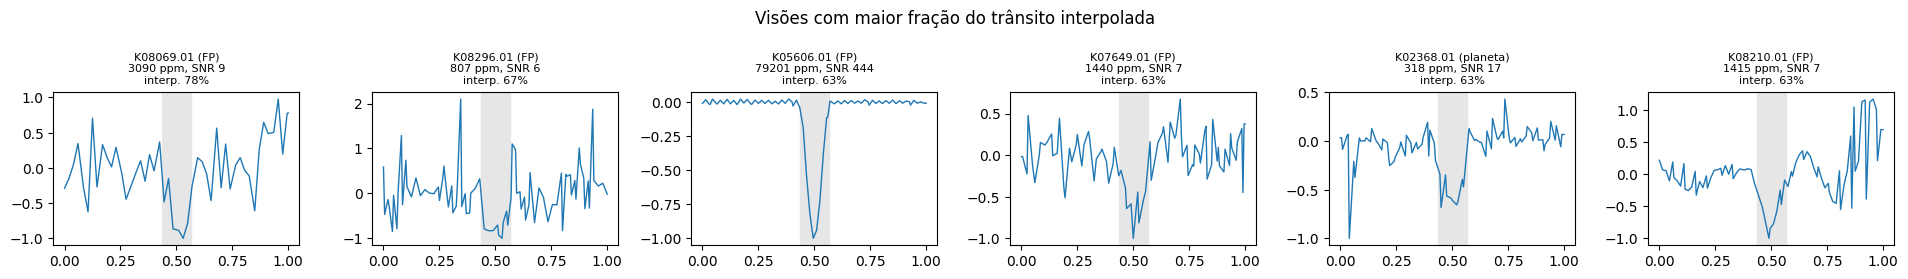

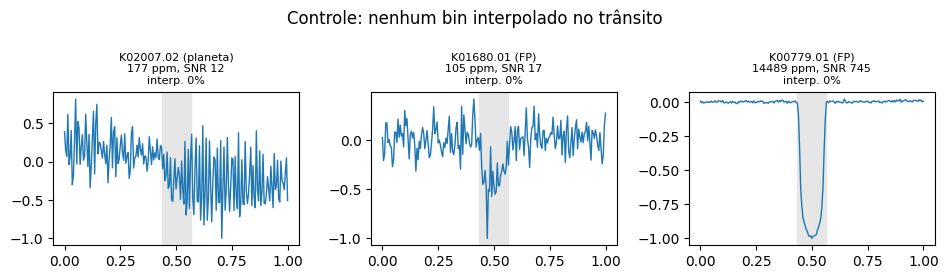

     kepoi_name   kepler_name  koi_depth  koi_model_snr  frac_interp_transito  \
188   K00183.01  Kepler-423 b    18136.5         2833.1                   0.0   
194   K00189.01  Kepler-486 b    21124.7         1126.2                   0.0   
1045  K00830.01  Kepler-428 b    22335.0         1996.7                   0.0   
1716  K01416.01  Kepler-840 b    25070.0          171.4                   0.0   

      frac_interp_fora  
188                0.0  
194                0.0  
1045               0.0  
1716               0.0  


In [ ]:
def plot_casos(df, titulo, arquivo):
    n = len(df)
    fig, axs = plt.subplots(1, n, figsize=(3.2 * n, 2.8), squeeze=False)
    for ax, (_, r) in zip(axs[0], df.iterrows()):
        l = np.load(f"{VIEWS_DIR}/{r.kepoi_name}.npz")['local_view']
        ax.plot(np.linspace(0, 1, LOCAL_BINS), l, lw=1)
        ax.axvspan(JANELA[0] / (LOCAL_BINS - 1), JANELA[-1] / (LOCAL_BINS - 1), color='0.9')
        classe = 'planeta' if r.label == 1 else 'FP'
        ax.set_title(f"{r.kepoi_name} ({classe})\n{r.koi_depth:.0f} ppm, SNR {r.koi_model_snr:.0f}\n"
                     f"interp. {r.frac_interp_transito:.0%}", fontsize=8)
    fig.suptitle(titulo); plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{arquivo}_{SUFIXO}.png', dpi=300); plt.show()

plot_casos(diag.sort_values('frac_interp_transito', ascending=False).head(6),
           'Visões com maior fração do trânsito interpolada', 'outliers_casos')
plot_casos(diag[diag.frac_interp_transito == 0].sample(3, random_state=0),
           'Controle: nenhum bin interpolado no trânsito', 'outliers_controle')

# Os casos do Nb09 devem aparecer como afetados (Kepler-840 b entra como comparacao):
print(diag[diag.kepler_name.isin(['Kepler-428 b', 'Kepler-486 b', 'Kepler-423 b', 'Kepler-840 b'])]
      [['kepoi_name', 'kepler_name', 'koi_depth', 'koi_model_snr', 'frac_interp_transito', 'frac_interp_fora']])

## 3. Relação com SNR, profundidade e classe

Se a causa é o corte a 6σ, a interpolação deve ser mais frequente em sinais profundos e de SNR alto, e portanto nos falsos positivos, cujos eclipses costumam ser mais profundos. Na rodada final esse padrão não aparece, porque as poucas visões afetadas são lacunas comuns de dados.

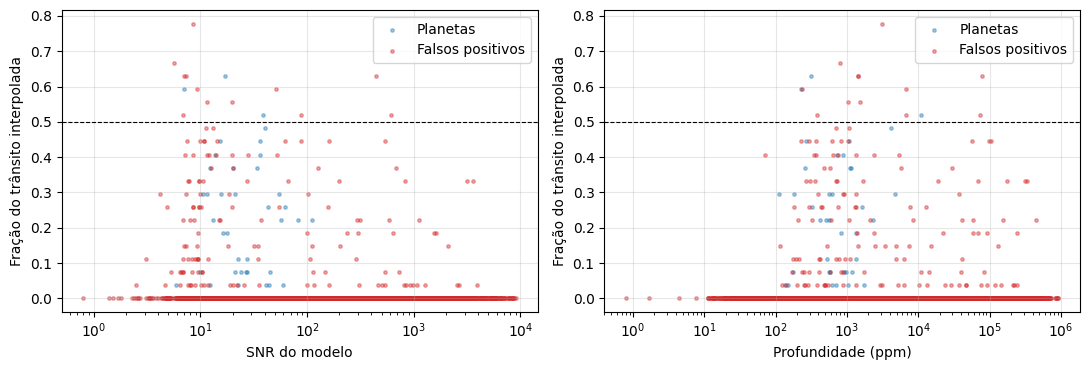

Mediana de SNR   -> afetados: 12 | demais: 35
Mediana de prof. -> afetados: 1440 ppm | demais: 535 ppm
Fracao de afetados por classe:
label
falsos positivos    0.3%
planetas            0.1%
Name: afetado, dtype: object


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for lab, cor, nome in [(1, 'tab:blue', 'Planetas'), (0, 'tab:red', 'Falsos positivos')]:
    s = diag[diag.label == lab]
    axs[0].scatter(s.koi_model_snr, s.frac_interp_transito, s=6, alpha=0.4, c=cor, label=nome)
    axs[1].scatter(s.koi_depth, s.frac_interp_transito, s=6, alpha=0.4, c=cor, label=nome)
for ax, xl in zip(axs, ['SNR do modelo', 'Profundidade (ppm)']):
    ax.set_xscale('log'); ax.set_xlabel(xl); ax.set_ylabel('Fração do trânsito interpolada')
    ax.axhline(AFETADO, ls='--', c='k', lw=0.8); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/outliers_snr_profundidade_{SUFIXO}.png', dpi=300); plt.show()

print('Mediana de SNR   -> afetados: %.0f | demais: %.0f' %
      (diag.loc[diag.afetado, 'koi_model_snr'].median(), diag.loc[~diag.afetado, 'koi_model_snr'].median()))
print('Mediana de prof. -> afetados: %.0f ppm | demais: %.0f ppm' %
      (diag.loc[diag.afetado, 'koi_depth'].median(), diag.loc[~diag.afetado, 'koi_depth'].median()))
print('Fracao de afetados por classe:')
print(diag.groupby('label')['afetado'].mean().rename({0: 'falsos positivos', 1: 'planetas'}).map('{:.1%}'.format))

## 4. Impacto nos erros do teste

Verifica se os modelos erram mais nas visões afetadas e se algum planeta perdido pela CNN está entre elas. Na primeira rodada, a CNN perdeu 6 dos 8 planetas afetados do teste; na rodada final, nenhum dos 18 planetas perdidos pela CNN foi afetado.

In [ ]:
pred = pd.read_csv(f'{DATA_DIR}/predicoes_teste.csv')
teste = pred.merge(diag[['kepoi_name', 'frac_interp_transito', 'afetado']], on='kepoi_name', how='left')
print('Teste:', len(teste), '| afetados no teste:', int(teste.afetado.sum()))

res = []
for arq in ['cnn1d', 'transformer', 'bilstm']:
    for grupo, sub in [('afetados', teste[teste.afetado == True]), ('nao afetados', teste[teste.afetado == False])]:
        res.append(dict(arquitetura=arq, grupo=grupo, n=len(sub),
                        taxa_erro=1 - sub[f'acerto_{arq}'].mean(),
                        fn_planetas=int(((sub.y == 1) & ~sub[f'acerto_{arq}']).sum()),
                        planetas=int((sub.y == 1).sum())))
res = pd.DataFrame(res)
res['taxa_erro'] = res['taxa_erro'].map('{:.1%}'.format)
print(res.to_string(index=False))

Teste: 670 | afetados no teste: 1
arquitetura        grupo   n taxa_erro  fn_planetas  planetas
      cnn1d     afetados   1      0.0%            0         0
      cnn1d nao afetados 669     10.6%           18       254
transformer     afetados   1      0.0%            0         0
transformer nao afetados 669     12.9%           37       254
     bilstm     afetados   1      0.0%            0         0
     bilstm nao afetados 669     13.0%           36       254


In [ ]:
# Falsos negativos da CNN: quantos sao afetados? (inclui os profundos do Nb09)
fn = teste[(teste.y == 1) & ~teste.acerto_cnn1d].sort_values('koi_depth', ascending=False)
print(f'Falsos negativos da CNN: {len(fn)} | afetados: {int(fn.afetado.sum())}')
print(fn[['kepoi_name', 'kepler_name', 'koi_depth', 'koi_model_snr', 'prob_cnn1d', 'frac_interp_transito']]
      .head(10).to_string(index=False))

# v1 mantem o nome original; v2 ganha sufixo, para nao sobrescrever o diagnostico da 1a rodada
arq_diag = 'diagnostico_outliers.csv' if SUFIXO == 'views' else f'diagnostico_outliers_{SUFIXO}.csv'
diag.to_csv(f'{DATA_DIR}/{arq_diag}', index=False)
print('\nSalvo:', arq_diag)

Falsos negativos da CNN: 18 | afetados: 0
kepoi_name   kepler_name  koi_depth  koi_model_snr  prob_cnn1d  frac_interp_transito
 K03728.01 Kepler-1517 b     2211.0           56.4    0.415441                   0.0
 K00408.01  Kepler-150 c     1433.8          101.6    0.385528                   0.0
 K01581.01  Kepler-896 c      879.9           39.5    0.079601                   0.0
 K04036.01 Kepler-1544 b      614.4           15.3    0.070251                   0.0
 K01989.01 Kepler-1040 b      584.8           34.7    0.005957                   0.0
 K01241.01   Kepler-56 c      409.3           60.9    0.496893                   0.0
 K02133.01   Kepler-91 b      396.8           63.6    0.060183                   0.0
 K02851.01 Kepler-1985 b      356.8           13.9    0.323148                   0.0
 K03113.01 Kepler-1430 b      276.8           16.7    0.351318                   0.0
 K00938.02  Kepler-255 d      213.0           25.3    0.322420                   0.0

Salvo: diagnostico_out

## 5. Confirmação da causa (opcional)

Reprocessa três alvos com o mesmo pipeline, mudando apenas o corte de *outliers* para remover só os pontos acima de 6σ (`sigma_lower=inf`). Se o fundo do trânsito reaparecer, a causa está confirmada. Precisa de internet e do `lightkurve==2.6.0` (cerca de 1 minuto por alvo) e não altera nenhum arquivo salvo.

In [ ]:
!pip -q install lightkurve==2.6.0

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


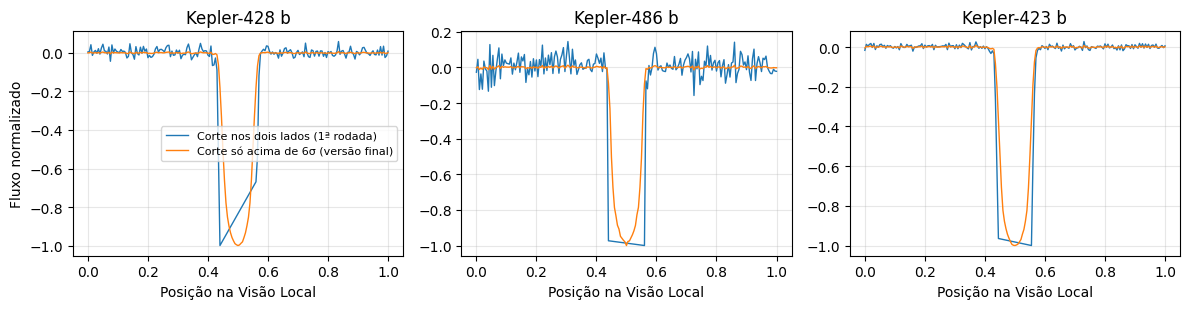

In [ ]:
import lightkurve as lk
from scipy.stats import binned_statistic

def median_bin(x, y, num_bins, x_min, x_max):
    stat, edges, _ = binned_statistic(x, y, statistic='median', bins=num_bins, range=(x_min, x_max))
    centers = 0.5 * (edges[:-1] + edges[1:])
    nans = np.isnan(stat)
    if nans.any() and not nans.all():
        stat[nans] = np.interp(centers[nans], centers[~nans], stat[~nans])
    return stat

def normalize_view(v):
    v = v - np.median(v)
    depth = np.abs(np.min(v))
    return v / depth if depth > 0 else v

def visao_local(row, sigma_lower):
    # Mesmo pipeline do Nb03; so o corte inferior de outliers varia.
    period, t0, dur = float(row.koi_period), float(row.koi_time0bk), float(row.koi_duration) / 24
    lcc = lk.search_lightcurve(f'KIC {int(row.kepid)}', mission='Kepler', author='Kepler',
                               cadence='long').download_all(flux_column='pdcsap_flux')
    lc = lcc.stitch().remove_nans()
    lc = lc.remove_outliers(sigma=6.0, sigma_lower=sigma_lower)
    mask = lc.create_transit_mask(period=period, transit_time=t0, duration=dur)
    folded = lc.flatten(window_length=901, mask=mask).fold(period=period, epoch_time=t0)
    ph, fl = np.asarray(folded.phase.value), np.asarray(folded.flux.value)
    ok = np.isfinite(ph) & np.isfinite(fl)
    half = min(K_DURATIONS * dur, period / 2)
    return normalize_view(median_bin(ph[ok], fl[ok], LOCAL_BINS, -half, half))

alvos = labels[labels.kepler_name.isin(['Kepler-428 b', 'Kepler-486 b', 'Kepler-423 b'])]
fig, axs = plt.subplots(1, len(alvos), figsize=(4 * len(alvos), 3.2), squeeze=False)
x = np.linspace(0, 1, LOCAL_BINS)
for ax, (_, r) in zip(axs[0], alvos.iterrows()):
    ax.plot(x, visao_local(r, sigma_lower=6.0),    lw=1, label='Corte nos dois lados (1ª rodada)')
    ax.plot(x, visao_local(r, sigma_lower=np.inf), lw=1, label='Corte só acima de 6σ (versão final)')
    ax.set_title(r.kepler_name); ax.grid(alpha=0.3)
for a in axs[0]: a.set_xlabel('Posição na Visão Local')
axs[0][0].set_ylabel('Fluxo normalizado')
axs[0][0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/outliers_antes_depois.png', dpi=300); plt.show()

## 6. Vazamento entre estrelas

Conta quantos KOIs do teste pertencem a estrelas com outros KOIs na amostra e quantas estrelas do teste também aparecem no treino. Na primeira rodada, com partição por KOI, 129 dos 273 planetas do teste (47%) tinham outro KOI da mesma estrela na amostra, quase sempre no treino. Na rodada final, com partição por estrela, nenhuma estrela do teste aparece no treino.

In [ ]:
n_por_estrela = labels.groupby('kepid').size()
teste['kepid'] = teste['kepoi_name'].map(labels.set_index('kepoi_name')['kepid'])
teste['irmaos'] = teste['kepid'].map(n_por_estrela) - 1
com = teste[teste.irmaos > 0]
print(f'KOIs do teste com outros KOIs da mesma estrela na amostra: {len(com)} de {len(teste)} '
      f'({len(com) / len(teste):.1%})')
print('  planetas:', int(com.y.sum()), '| falsos positivos:', int((com.y == 0).sum()))
print(f'Estrelas com mais de um KOI na amostra: {(n_por_estrela > 1).sum()} de {len(n_por_estrela)}')

# Estrelas compartilhadas entre teste e treino (o dataset.npz atual grava o kepid de cada conjunto)
d = np.load(f'{DATA_DIR}/dataset.npz')
if 'kepid_train' in d.files:
    comuns = set(d['kepid_test'].tolist()) & set(d['kepid_train'].tolist())
    print(f'Estrelas do teste que tambem aparecem no treino: {len(comuns)}')

KOIs do teste com outros KOIs da mesma estrela na amostra: 145 de 670 (21.6%)
  planetas: 122 | falsos positivos: 23
Estrelas com mais de um KOI na amostra: 583 de 5828
Estrelas do teste que tambem aparecem no treino: 0


## Conclusão

O corte simétrico de *outliers* afetou 10,4% das visões na primeira rodada, a maioria de falsos positivos, proporção que permitia aos modelos associar o fundo reto do trânsito à classe negativa. Com o corte restrito ao lado superior, as visões afetadas caíram para 0,2%, todas por lacunas comuns de dados. A partição por estrela eliminou o vazamento entre treino e teste. As duas correções foram aplicadas juntas na rodada final (notebook 03).